In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import osmnx as ox
import openrouteservice as ors

from utils import AreaClass

from dotenv import load_dotenv, dotenv_values
load_dotenv()
ors_key = os.getenv('ORS_KEY')
ors_client = ors.Client(key=ors_key)

In [21]:
places = ["Vilnius, Lithuania", "Kaunas, Lithuania", "Riga, Latvia", "Tallinn, Estonia"]
stats = []

for key, place in enumerate(places):
    places[key] = AreaClass(place)
    stats.append(places[key].stats)

stats = pd.DataFrame(stats)

# Some columns are not needed.
cols = ['n', 'm', 'k_avg', 'edge_length_total', 'edge_length_avg',
       'streets_per_node_avg', 'intersection_count',
       'street_length_total', 'street_segment_count', 'street_length_avg',
       'circuity_avg', 'self_loop_proportion', 'node_density_km',
       'intersection_density_km', 'edge_density_km', 'street_density_km']

In [24]:
pd.options.display.float_format = '{:.2f}'.format
stats[cols].transpose()

,"Vilnius, Lithuania","Kaunas, Lithuania","Riga, Latvia","Tallinn, Estonia"
n,8009.00,4903.00,9682.00,6937.00
m,18699.00,11565.00,23747.00,16159.00
k_avg,4.67,4.72,4.91,4.66
edge_length_total,3458427.81,1739790.41,2950231.13,1903675.09
edge_length_avg,184.95,150.44,124.24,117.81
streets_per_node_avg,2.64,2.69,2.76,2.88
intersection_count,6118.00,3869.00,8028.00,5924.00
street_length_total,1906217.31,945697.67,1671126.89,1129433.21
street_segment_count,10486.00,6533.00,13344.00,9975.00
street_length_avg,181.79,144.76,125.23,113.23


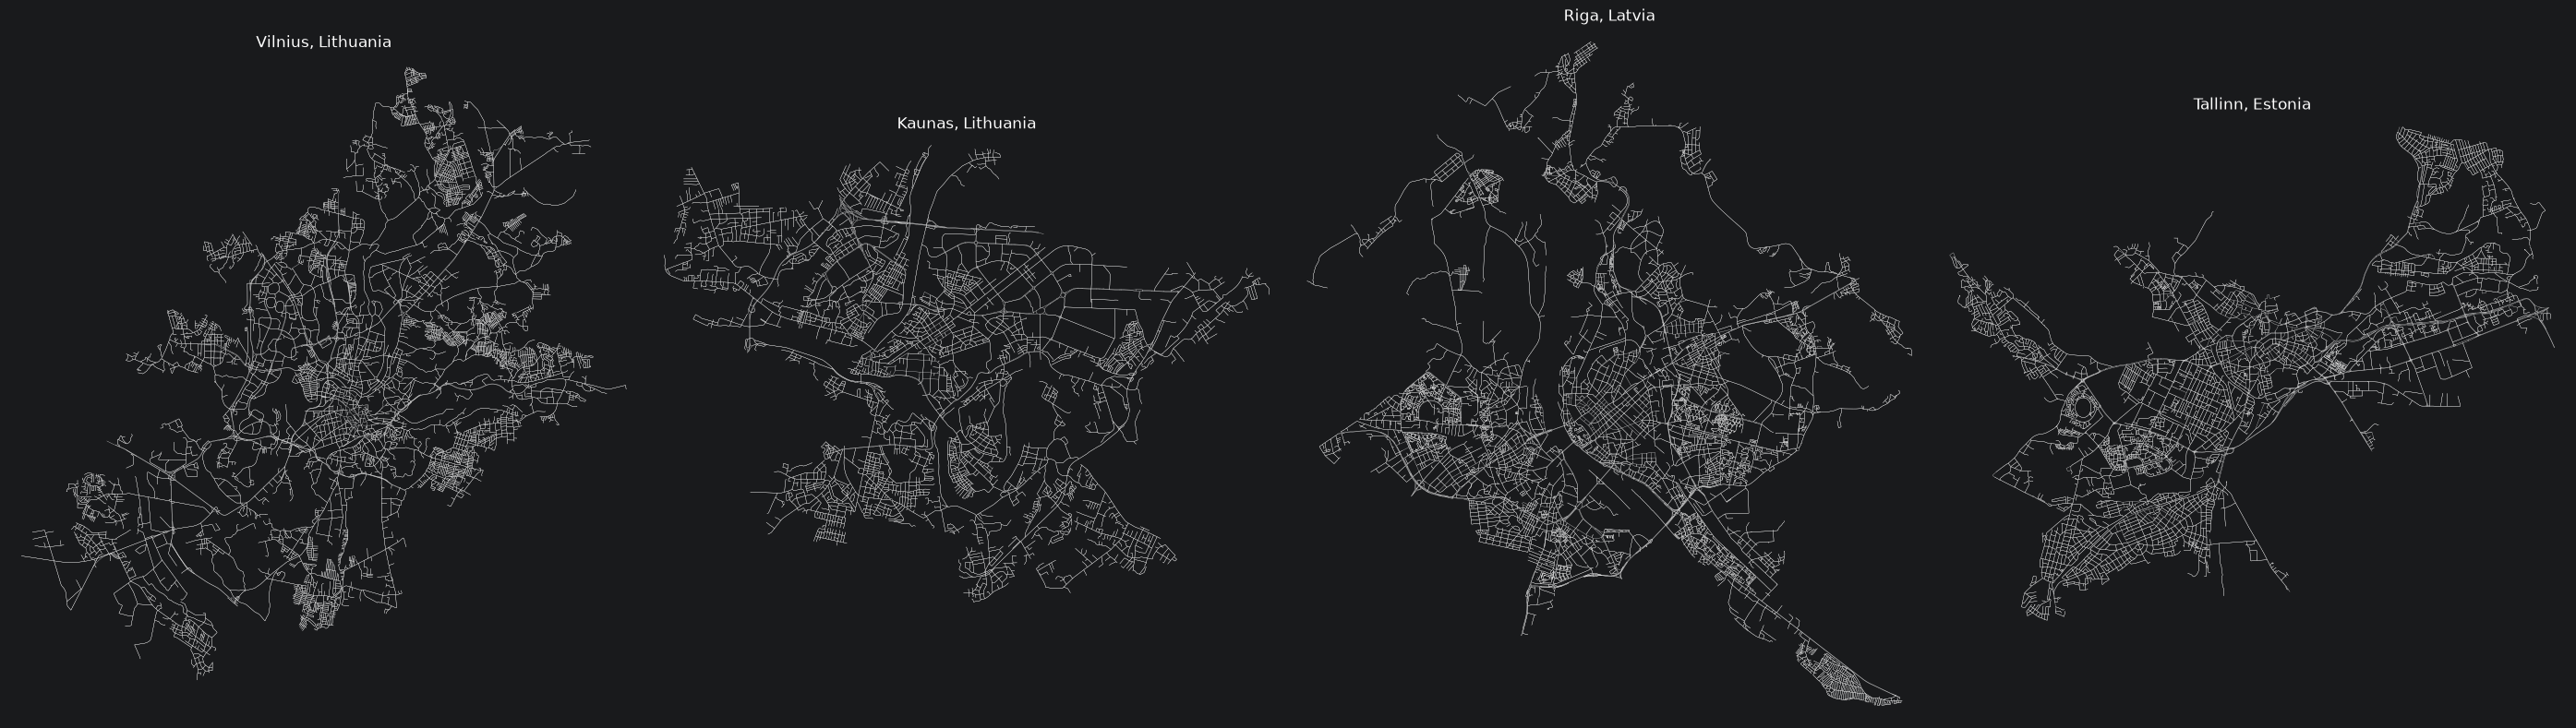

In [25]:
fig, axs = plt.subplots(1,len(places), figsize=(len(places) * 7,12))

for key, place in enumerate(places):
    ox.plot_graph(place.G, node_size=0, edge_color="w", edge_linewidth=0.2, ax=axs[key], show=False)
    axs[key].set_title(place.name)

plt.tight_layout()
plt.show()

In [22]:
import networkx as nx

G = places[0].G
# calculating the betweenness centrality for Vilnius, Lithuania.
bc = nx.betweenness_centrality(ox.convert.to_digraph(G), weight="length")
max_node, max_bc = max(bc.items(), key=lambda x: x[1])
max_node, max_bc


(32872380, 0.1676714380910709)

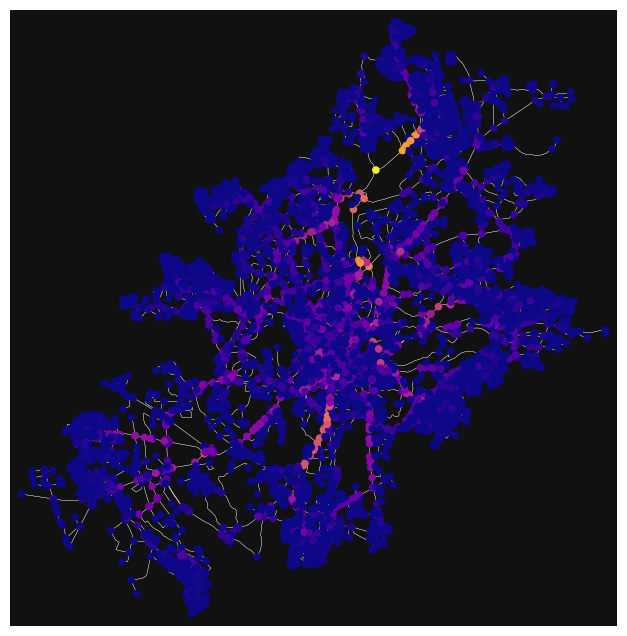

In [23]:
G = places[0].G

nx.set_node_attributes(G, bc, "bc")
nc = ox.plot.get_node_colors_by_attr(G, "bc", cmap="plasma")
fig, ax = ox.plot.plot_graph(
    G,
    node_color=nc,
    node_size=30,
    node_zorder=2,
    edge_linewidth=0.2,
    edge_color="w",
)